In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import warnings as wr
wr.filterwarnings("ignore")

In [2]:
df = pd.read_excel("Dhaka Rent.xlsx")


In [3]:
df.head()

,area,rent
0,2000,31500
1,2100,35000
2,2500,41050
3,2250,36100
4,3000,52100


In [9]:
df.shape

(60, 2)

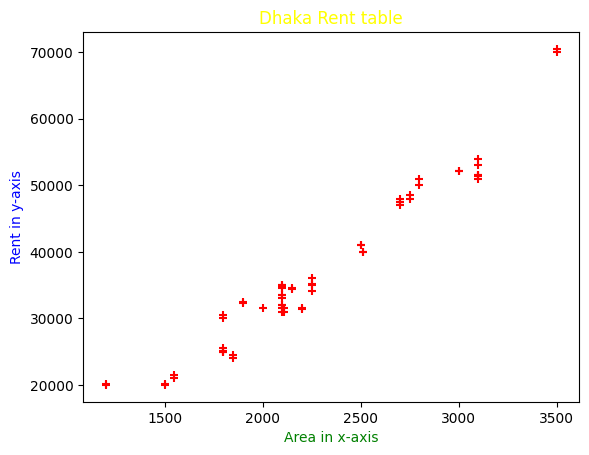

In [65]:
plt.scatter(df.area,df.rent,color="red",marker="+")
plt.xlabel("Area in x-axis",color="green")
plt.ylabel("Rent in y-axis",color="blue")
plt.title("Dhaka Rent table",color="yellow")
plt.show()

In [4]:
x=df.drop("rent",axis=1)
y=df[['rent']]


In [5]:
x.head()
#x.shape

,area
0,2000
1,2100
2,2500
3,2250
4,3000


In [6]:
x.mean()

area    2289.0
dtype: float64

In [7]:
y.head()

,rent
0,31500
1,35000
2,41050
3,36100
4,52100


In [8]:
y.mean()

rent    37269.166667
dtype: float64

In [9]:
from sklearn.model_selection import train_test_split

In [10]:
train,test=train_test_split(df,test_size=.25)

In [11]:
train.shape

(45, 2)

In [12]:
train.head()

,area,rent
21,2100,33500
32,2500,41100
4,3000,52100
11,2100,32000
19,2700,47000


In [13]:
test.shape

(15, 2)

In [14]:
test.head()

,area,rent
14,2250,34100
15,3100,51500
10,2150,34500
30,2100,33500
41,2100,32020


In [15]:
xtrain, xtest, ytrain, ytest = train_test_split(x,y,test_size=.25,random_state=42)

In [16]:
xtrain.head()

,area
17,1550
8,2700
6,1500
40,2150
4,3000


In [17]:
ytrain.head()

,rent
17,21000
8,48000
6,20000
40,34400
4,52100


In [18]:
 xtest.head()

,area
0,2000
5,1900
36,1500
45,3100
13,2510


In [19]:
ytest.head()

,rent
0,31500
5,32500
36,20200
45,51000
13,40050


In [20]:
#LinearRegression
from sklearn.linear_model import LinearRegression

In [21]:
lr=LinearRegression() #Lr is the object of linear regression model

In [22]:
lr.fit(xtrain,ytrain) #Training the model

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [23]:
m=lr.coef_
m

array([[20.85430218]])

In [24]:
c=lr.intercept_
c

array([-10622.30337927])

In [25]:
yp=(m*1550)+c
yp

array([[21701.86499584]])

In [26]:
lr.predict([[1550]])

array([[21701.86499584]])

In [27]:
df["predicted_rent"]=lr.predict(x)
df.head()


,area,rent,predicted_rent
0,2000,31500,31086.300976
1,2100,35000,33171.731193
2,2500,41050,41513.452064
3,2250,36100,36299.876520
4,3000,52100,51940.603153


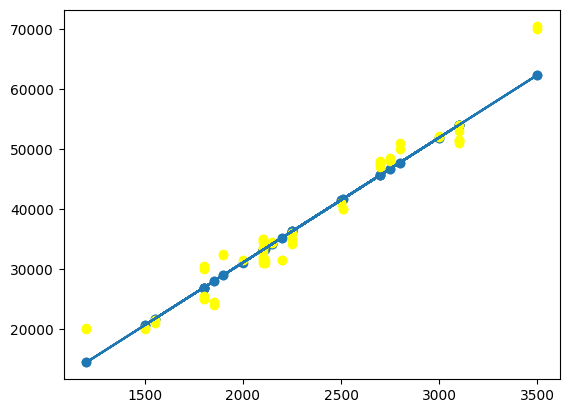

In [28]:
#Best Fit line
plt.plot(x,df[["predicted_rent"]])
plt.scatter(x,df[["predicted_rent"]])
plt.scatter(x,df[["rent"]],color="yellow")
plt.show()

In [29]:
from sklearn.metrics import mean_squared_error,mean_absolute_error

In [31]:
mse=mean_squared_error(ytest,lr.predict(xtest))

mae=mean_absolute_error(ytest,lr.predict(xtest))
mae,mse

(2246.3010039678825, 8549932.857090542)

In [32]:
lr.score(xtest,ytest)

0.9424228944888952

In [33]:
#Save ai model using pickle in our directory
#pickle are used when we have so many numpy array
import pickle
pickle.dump(lr,open('linear_regression','wb')) #wb mean is the write binary

In [34]:
#save model using joblib
#joblib are used when we have small amount of numpy array
import joblib as jb
jb.dump(lr,"linear_regression1")

['linear_regression1']